# 1. Problem

Recover three conditional lifetime components and two Gaussian timing-response components from actual pure-tin positron histograms. The bulk lifetime is short compared with the instrumental width, so material and response parameters are fitted jointly. No independent microscopic lifetime truth exists. Six increasing count conditions are cumulative acquisitions, not independent samples.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_data,prepare
from src.physics_model import residual
from src.visualization import spectra_figure,parameter_figure,residual_figure,prompt_figure
import importlib.util
s=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(s);s.loader.exec_module(judge)
print(sys.executable)

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


# 2. Data

The original measurement supplement supplies all six real5ps/channel histograms plus a separately measured Co-60quasi prompt response. Native integer counts remain unchanged. The selected published analysis branch sums10channels to50psbins, retaining all raw channels publicly. The fitting window and background-initialization region are fixed in the source; no measured count is replaced by a synthetic value.

The paper also reports native5psfitting and simulated spectra. This task binds its complete real50psanalysis branch across all6count conditions; those other branches are not claimed as reproduced. All native observations remain supplied, and the bin10selection was fixed before source/local execution.


In [2]:
counts,prompt,observed=load_data(ROOT/'data/raw_data.npz')
print('Raw',counts.shape,counts.dtype,'binned',observed.shape)
print('Actual measured totals:',counts.sum(1))
assert np.array_equal(counts.sum(1),observed.sum(1))
print('Independent prompt counts:',prompt.sum())

Raw (6, 10000) int64 binned (6, 1000)
Actual measured totals: [ 527962 1003525 1501263 2015807 2474264 2787804]
Independent prompt counts: 59171


# 3. Physics

For lifetime tau, Gaussian mean m and Gaussian standard deviation sigma, the bin-integrated response uses the cumulative distribution

$$
H(t)=\Phi(z)-\exp\left(-\frac{t-m}{\tau}+\frac{\sigma^2}{2\tau^2}\right)\Phi\left(z-\frac{\sigma}{\tau}\right),\quad z=(t-m)/\sigma.
$$

Phi is the standard normal CDF. All times are ps, sigma=FWHM/(2sqrt(2ln2)). Weighted differences H(t+50)-H(t) are summed over the three lifetime and two response components. Their amplitude is S-916B, where S is measured count in bins33through948and B is fitted counts/bin. The Gaussian means are relative to bin33left edge. The independent prompt is diagnostic only: sample-fitted response parameters are never promoted into known calibration.


# 4. Method

The selected source objective is

$$
J=\sum_{b=33}^{946}\frac{(y_b-v_b)^2}{y_b+1}+10^8(c_1+c_2-1)^2.
$$

Here y is observed counts, v is modeled counts and c are response mixture coefficients. The original callback's two histogram-edge bins contribute to its total area but not its residual; this convention is explicit, not fit-dependent selection. Source and local implementations use this exact objective and complete restart budget. The original MPFIT-C and local general SciPy Levenberg-Marquardt can take different paths; acceptance uses scientific objective quality and all-output forward consistency. Sorting removes only component-label permutations.


In [3]:
start=time.perf_counter()
counts,prompt,observed,parameters,predicted,histories=run(ROOT)
print('Fresh six-condition reconstruction seconds:',time.perf_counter()-start)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz');assert exit_code==0
print(json.dumps(report,indent=2))

Fresh six-condition reconstruction seconds: 1.5492215999402106
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "objective_0": 998.1364854437402,
    "forward_observation_normalized_l2_0": 9.572176651697558e-15,
    "objective_1": 1077.0392694666084,
    "forward_observation_normalized_l2_1": 9.313622981162216e-15,
    "objective_2": 1076.1816318792971,
    "forward_observation_normalized_l2_2": 9.336620711751317e-15,
    "objective_3": 1068.2709738138713,
    "forward_observation_normalized_l2_3": 9.418762807201241e-15,
    "objective_4": 1079.541402309705,
    "forward_observation_normalized_l2_4": 9.71710479944251e-15,
    "objective_5": 1077.7807277706834,
    "forward_observation_normalized_l2_5": 1.0257833160387527e-14
  },
  "thresholds": {
    "objective_0": {
      "comparison": "<=",
      "boundary": 998.6355536550473
    },
    "forward_observation_normalized_l2_0": {
      "comparison": "<=",
      "boundary": 1e-09
    },
    "objective_1": {
      "comparison":

# 5. Results

Independent original C++run results are method references, not physical truth. Historical rounded paper bulk lifetimes are contextual comparisons; source code revision and weighting are recorded separately. Every fresh curve and plotted parameter below was computed above. Cumulative acquisition conditions share counts and must not be treated as independent replicate statistics.

Nominal kcounts | historical paper bulk ps (rounded) | original run bulk ps | fresh bulk ps | original objective | fresh objective
500 194.0 193.97596736237477 193.9762777869084 998.1364854123411 998.1364854441116
1000 196.3 196.33575607806824 196.33585321468462 1077.03926945847 1077.0392694669665
1500 191.9 191.81917846880629 191.81916178544094 1076.1816318857275 1076.1816318788153
2000 193.7 193.57978923244247 193.57933402393792 1068.2709738166907 1068.270973814421
2500 191.9 191.84177944515096 191.84171321607352 1079.5414023047115 1079.5414023098465
2800 191.5 191.52539744300176 191.52550890419994 1077.780727790818 1077.7807277711


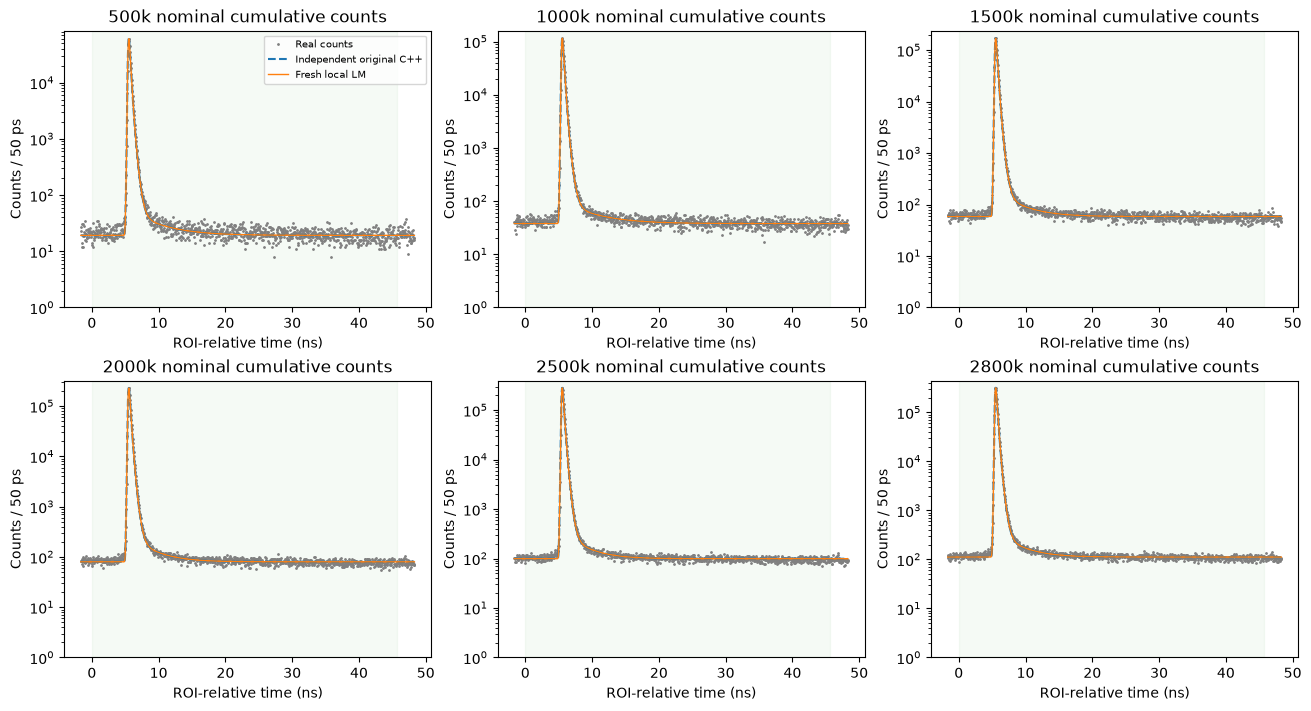

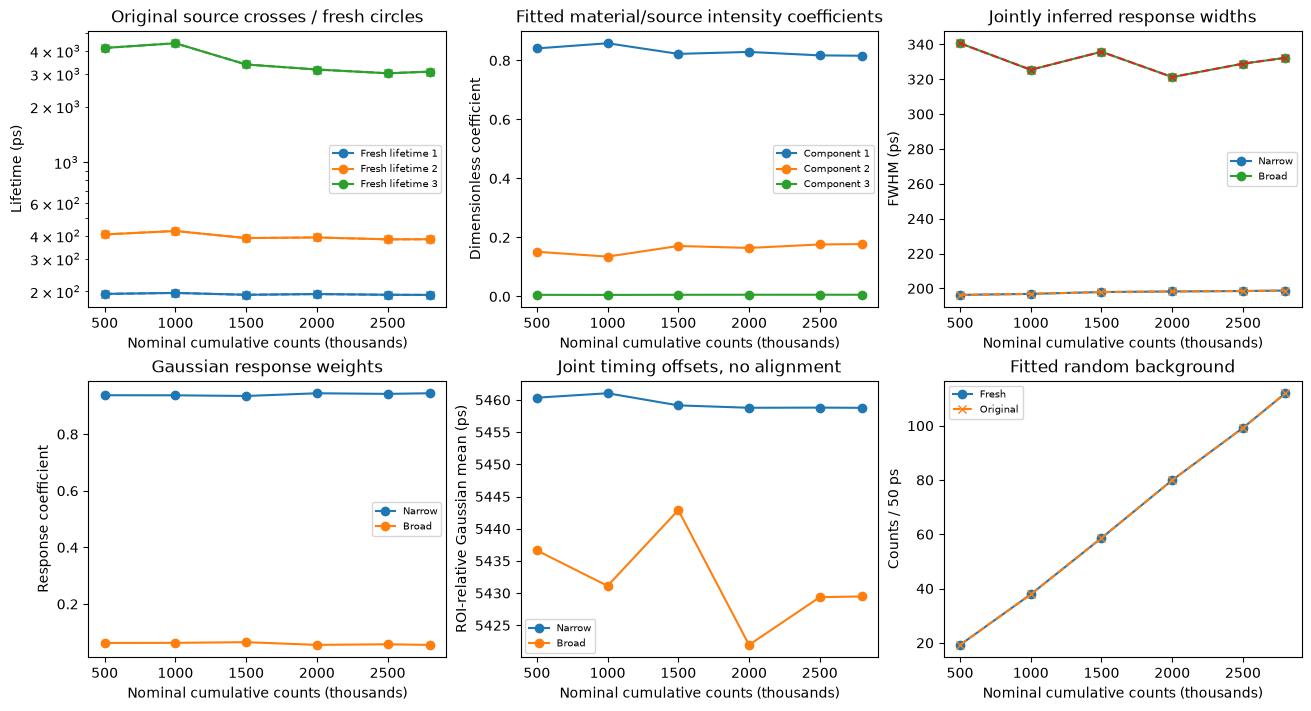

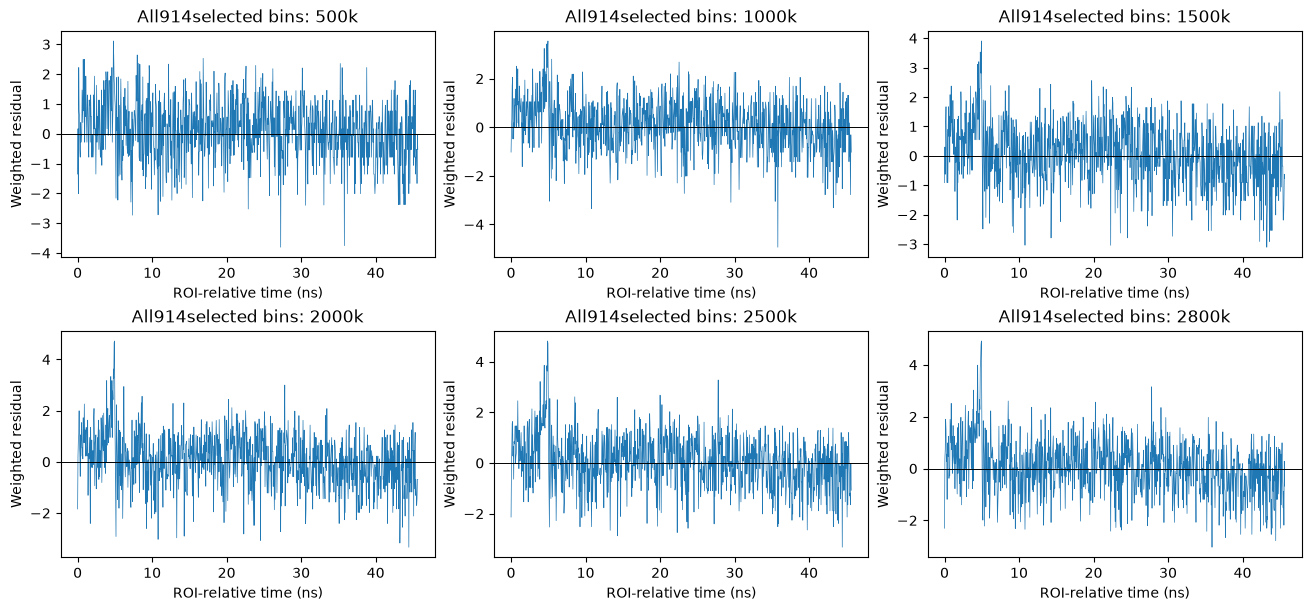

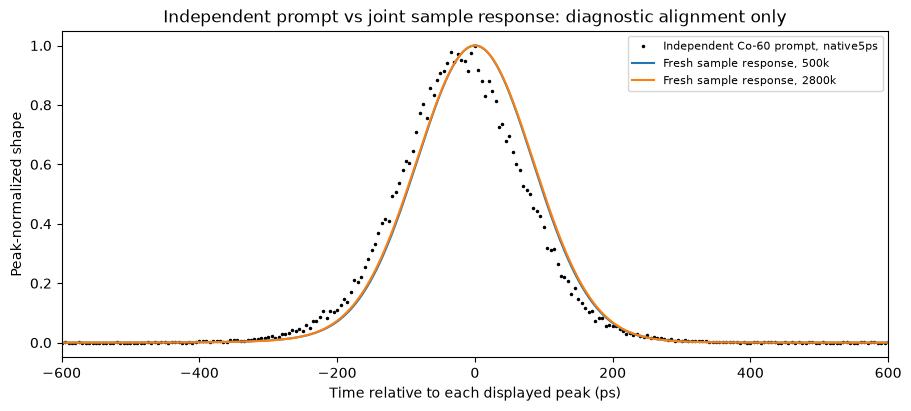

In [4]:
up=np.load(ROOT/'notebooks/reference_outputs/upstream.npz')
area,_=prepare(observed)
print('Nominal kcounts | historical paper bulk ps (rounded) | original run bulk ps | fresh bulk ps | original objective | fresh objective')
for i,(nom,hist) in enumerate(zip([500,1000,1500,2000,2500,2800],[194.,196.3,191.9,193.7,191.9,191.5])):
 print(nom,hist,up['output_parameters_native'][i,0]*50,parameters[i,0]*50,up['output_objective'][i],np.sum(residual(parameters[i],observed[i],area[i])**2))
fig=spectra_figure(observed,predicted,up['output_prediction']);plt.show()
fig2=parameter_figure(parameters,up['output_parameters_native']);plt.show()
fig3=residual_figure(observed,predicted);plt.show()
fig4=prompt_figure(prompt,parameters);plt.show()

# 6. Conclusion

The full local inversion agrees with independently executed original numerical kernels on all six measured histograms. Count conservation, bin integration, the zero-width exponential limit and an independent normal-CDF Judge support mathematical correctness beyond copied-formula parity. Three decay contributions and the response remain conditional mixture estimates; no claim of uniquely resolved microscopic states or independent material truth follows from objective agreement. Prompt-vs-sample shape differences and the cumulative nature of the count conditions are retained as limitations. Diagnostic peak alignment appears only in the response-shape figure; evaluation never aligns the submitted timing means.